# Topology optimization with a metal: a waveguide bend in gold and oxide over 1.5-1.6 µm

**Question.** The {doc}`bend tutorial <bend>` turns light round a 90° corner with
core material placed by gradients in a 3 µm square. Here the square holds gold
instead: each point is cladding or gold. Can gold, placed by gradients, turn 1.5 to
1.6 µm light round the corner, and what does its absorption cost?

Gold's permittivity is negative, and it changes by about 14 % across the band. One
driven solve takes all three wavelengths of the band, each with gold's own
permittivity there, and its gradient with respect to every pixel of the design.

The chain from pixels to the objective is the bend tutorial's, with a metal at
the end:

pixels ρ → **mirror** about y = x → **Helmholtz filter** → **projection** →
**layer grid** → **index blend** of cladding and gold → {py:func}`gfem.solve` over
the band → |S21|².

**Assumptions.**

- The bend tutorial's slab model: a top view in effective indices (core 2.25,
  cladding 1.444), one element thick between PEC plates, so the electric field is
  along z.
- Gold as a Drude metal with rounded parameters: a plasma frequency of
  2.183 × 10¹⁵ Hz and a damping of 1.28 × 10¹³ Hz. It is a gold-like metal, not a
  fitted data set.
- E along z is tangential to every gold wall in the plane. Gold then acts as a
  lossy mirror: this polarization has no surface plasmon.
- The mesh does not resolve gold's skin depth (about 22 nm against 0.1 µm cells).
  The checks below bound what the elements cost, not what the cell size costs.
- Lossless dielectrics: gold is the only absorber.

**Conventions.** SI units at the API (the mesh file is in µm), time dependence
e^{+iωt}, so a lossy permittivity has Im ε < 0. Law frequencies are in Hz.
S-parameters are power waves normalized to 1 W of mode power at each wave port. See
{py:mod}`gfem.conventions`.

In [1]:
import time
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
from contourpy import contour_generator
from scipy.constants import c

import gfem
from gfem import design

um = 1e-6
BAND = np.array([1.50, 1.55, 1.60]) * um  # the wavelengths the objective sees
F_BAND = c / BAND
F0 = F_BAND[1]  # 1.55 um, 193.4 THz

## The gold

A {py:class}`gfem.PermittivityLaw` is a high-frequency permittivity plus dispersion
terms. Gold here is one {py:class}`gfem.Drude` term, with its frequencies in Hz:

ε(f) = ε∞ - f_p² / (f (f - i γ)),

with ε∞ = 1, f_p the plasma frequency and γ the damping. A law is callable:
`law(f)` is the complex relative permittivity at `f`. The skin depth, the depth
over which the field in the metal falls by 1/e, is λ / (2πκ), with n - iκ = √ε.

In [2]:
gold_law = gfem.PermittivityLaw(
    eps_inf=1.0, terms=[gfem.Drude(plasma_frequency=2.183e15, damping=1.28e13)]
)
N_CORE, N_CLADDING, WIDTH = 2.25, 1.444, 0.55 * um
CLADDING = gfem.Material(eps_r=N_CLADDING**2, name="cladding")
CORE = gfem.Material(eps_r=N_CORE**2, name="core")
GOLD = gfem.Material(eps_r=gold_law, name="gold")

eps_band = np.asarray(gold_law(F_BAND))
for wavelength, eps in zip(BAND, eps_band, strict=True):
    kappa = -np.sqrt(eps).imag
    print(
        f"{wavelength / um:.2f} um: eps = {eps.real:.2f} {eps.imag:+.2f}j, "
        f"skin depth = {wavelength / (2 * np.pi * kappa) / 1e-9:.1f} nm"
    )

1.50 um: eps = -117.81 -7.61j, skin depth = 22.0 nm
1.55 um: eps = -125.83 -8.39j, skin depth = 22.0 nm
1.60 um: eps = -134.11 -9.23j, skin depth = 22.0 nm


Re ε and Im ε from 1.2 to 1.8 µm; the shaded band is the one the objective sees.

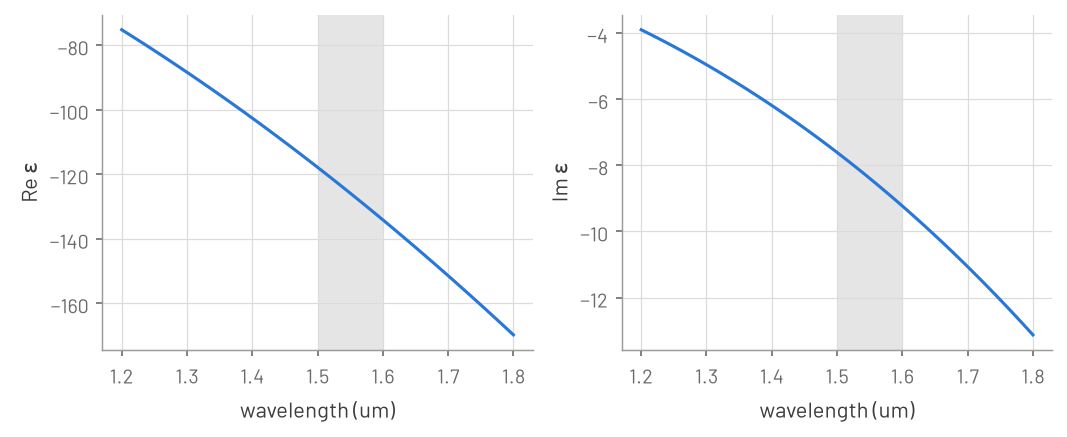

In [3]:
span = np.linspace(1.2, 1.8, 121) * um
eps_span = np.asarray(gold_law(c / span))
fig, axes = plt.subplots(1, 2, figsize=(7, 2.8), layout="constrained")
for ax, part, label in (
    (axes[0], eps_span.real, "Re ε"),
    (axes[1], eps_span.imag, "Im ε"),
):
    ax.plot(span / um, part)
    ax.axvspan(BAND[0] / um, BAND[-1] / um, color="gray", alpha=0.2, lw=0)
    ax.set_xlabel("wavelength (um)")
    ax.set_ylabel(label)

## The bend

The model is the bend tutorial's, read from {download}`data/bend.msh`: a
5 µm × 5 µm × 0.1 µm box, the `"design"` volume (|x|, |y| < 1.5 µm) between the
input guide along x < -1.5 µm and the output guide along y < -1.5 µm, wave ports
`"p1"` and `"p2"` on the two guide ends, a second-order absorbing boundary on every
other side face, and PEC plates.

The design square sits 1 µm from both port faces and from the absorbing boundary,
so gold never touches either. That matters: a metal may not cross a wave port's
face, and the ports here see only core and cladding.

In [4]:
mesh = gfem.Mesh.from_gmsh(Path("data/bend.msh"), length_unit="um")
bend = gfem.Model(
    mesh,
    materials={"cladding": CLADDING, "core": CORE, "design": CLADDING},
    boundaries=[gfem.PEC("plates"), gfem.Absorbing("outer", order=2)],
    ports=[
        gfem.WavePort("p1", "port1", pec_edges=("outer",)),
        gfem.WavePort("p2", "port2", pec_edges=("outer",)),
    ],
)
grid = design.LayerGrid(mesh, "design", pitch=0.05 * um)
bend

Model(Mesh(5618 nodes, 16224 tetrahedra, volumes=['cladding', 'core', 'design'], surfaces=['outer', 'plates', 'port1', 'port2'], length_unit='um')
  materials:
    cladding: Material(eps_r=2.085136, name='cladding')
    core: Material(eps_r=5.0625, name='core')
    design: Material(eps_r=2.085136, name='cladding')
  boundaries:
    PEC(surface='plates')
    Absorbing(surface='outer', order=2)
  ports:
    WavePort(name='p1', surface='port1', mode=1, offset=0.0, voltage_path=None, pec_edges=('outer',))
    WavePort(name='p2', surface='port2', mode=1, offset=0.0, voltage_path=None, pec_edges=('outer',)))

## From pixels to a material

A pixel value of 0 is cladding and 1 is gold. Between them,
{py:meth}`gfem.MaterialField.interpolate` with `scheme="index"` blends the
refractive index, not the permittivity: n - iκ is linear in ρ, and ε is its square.
The blend keeps gold's law, so each wavelength of the band sees gold's own
permittivity there.

Why not a linear blend of ε? Between ε = 2.09 and ε = -126, a linear blend passes
through Re ε ≈ -2 ε_cladding, where a small grey element is a plasmonic resonator,
almost lossless. An optimizer finds such artificial resonances. Under the index
blend a grey element has a large κ instead: it absorbs.

The cost of that choice: ρ = 0.5 is not a neutral start. Three designs show it, each
solved over the band:

- **all cladding**: ρ = 0 everywhere, the guides end in the open square;
- **half**: ρ = 0.5 everywhere, the bend tutorial's start;
- **mirror**: a 45° gold mirror behind the guides' crossing, gold where
  x + y > 0.6 µm, with each pixel holding its area fraction of gold.

`band_transmission` gives |S21|² at the three wavelengths.

In [5]:
problem = gfem.Driven(frequency=F_BAND, excite="p1")
options = gfem.SolverOptions(linear_solver="direct")


def material(density, gold=GOLD):
    # The design volume: 0 cladding, 1 gold, blended by refractive index.
    return gfem.MaterialField.interpolate(
        grid.to_elements(density), CLADDING, gold, scheme="index"
    )


def band_transmission(density):
    s = gfem.solve(
        bend.with_material("design", material(density)), problem, options=options
    ).s
    return jnp.abs(s["p2", "p1"]) ** 2


def area_fraction(inside, x, y, pitch, samples=8):
    # Per pixel centred at (x[j], y[i]): the fraction of its area where inside(x, y).
    offsets = ((np.arange(samples) + 0.5) / samples - 0.5) * pitch
    xs = x[None, :, None, None] + offsets[None, None, None, :]
    ys = y[:, None, None, None] + offsets[None, None, :, None]
    return inside(xs, ys).mean(axis=(2, 3))


mirror = area_fraction(lambda x, y: (x + y) > 0.6 * um, grid.x, grid.y, grid.pitch)
starts = {
    "all cladding": np.zeros(grid.shape),
    "half": np.full(grid.shape, 0.5),
    "mirror": mirror,
}
t_start = {}
for name, density in starts.items():
    t_start[name] = np.asarray(band_transmission(jnp.asarray(density)))
    print(f"{name:12s} |S21|^2 = " + " ".join(f"{t:.3g}" for t in t_start[name]))

all cladding |S21|^2 = 0.0165 0.0191 0.0192


half         |S21|^2 = 3.8e-12 1.29e-11 2.77e-11


mirror       |S21|^2 = 0.224 0.211 0.193


At ρ = 0.5 the square is an absorber: |S21|² is of order 10⁻¹¹, and so is the
gradient. The optimization starts from the mirror instead, which already sends a
fifth of the power round the corner.

The layout of the mirror start: the guides (white), gold (gold) and cladding (dark),
with the port faces p1 (solid) and p2 (dashed).

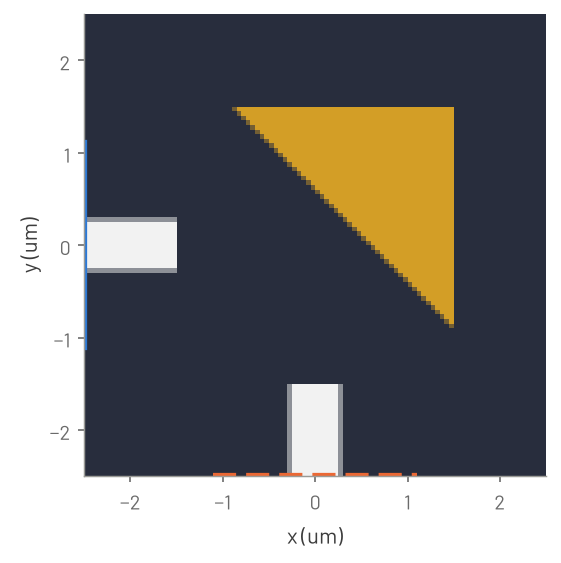

In [6]:
HALF = 2.5 * um  # the box's half-width
centres = -HALF + (np.arange(round(2 * HALF / grid.pitch)) + 0.5) * grid.pitch
corner_pixel = round((grid.origin[0] + HALF) / grid.pitch)  # same in x and y
inside_design = np.s_[
    corner_pixel : corner_pixel + grid.shape[0],
    corner_pixel : corner_pixel + grid.shape[1],
]
EXTENT = np.array([-HALF, HALF, -HALF, HALF]) / um
COLOURS = {  # RGB of each material in the layout images
    "cladding": np.array([0.16, 0.18, 0.24]),
    "core": np.array([0.95, 0.95, 0.95]),
    "gold": np.array([0.83, 0.62, 0.15]),
}


def in_arms(x, y):
    # The fixed guides: the input along x < -1.5 um, the output along y < -1.5 um.
    guide = WIDTH / 2
    return ((x < -1.5 * um) & (np.abs(y) <= guide)) | (
        (y < -1.5 * um) & (np.abs(x) <= guide)
    )


ARMS = area_fraction(in_arms, centres, centres, grid.pitch)


def layout(density):
    # The 5 um x 5 um box as an RGB image: the guides around a gold density.
    gold = np.zeros_like(ARMS)
    gold[inside_design] = np.asarray(density)
    clad = 1 - ARMS - gold
    return (
        clad[..., None] * COLOURS["cladding"]
        + ARMS[..., None] * COLOURS["core"]
        + gold[..., None] * COLOURS["gold"]
    )


nodes = np.asarray(mesh.nodes) / um
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(layout(mirror), origin="lower", extent=EXTENT)
for face, colour, style in (("port1", "C0", "-"), ("port2", "C1", "--")):
    xy = nodes[mesh.triangles[mesh.elements(face)]].reshape(-1, 3)[:, :2]
    lo, hi = xy.min(axis=0), xy.max(axis=0)
    ax.plot([lo[0], hi[0]], [lo[1], hi[1]], color=colour, ls=style, lw=3)
ax.set_xlabel("x (um)")
ax.set_ylabel("y (um)")
ax.grid(False);

## The objective

The objective is the power that misses the output guide's fundamental mode,
averaged over the band: the mean of 1 - |S21|² at 1.50, 1.55 and 1.60 µm. One
driven solve gives all three, and `jax.value_and_grad` gives its gradient with
respect to every pixel through one adjoint solve per wavelength.

`physical` maps the design parameters to the density the solve sees, as in the bend
tutorial: mirror about y = x (the design keeps the bend's symmetry), a Helmholtz
filter of radius 0.3 µm, and a projection towards 0 or 1 with sharpness β.

In [7]:
blur = design.helmholtz_filter(grid, radius=0.3 * um)


def physical(rho, beta):
    # Design parameters -> physical density: mirror about y = x, filter, project.
    return design.project(blur(0.5 * (rho + rho.T)), beta)


def loss(rho, beta):
    t = band_transmission(physical(rho, beta))
    return jnp.mean(1 - t), t  # band-mean missed power; aux: |S21|^2 per wavelength


value_and_grad = jax.jit(jax.value_and_grad(loss, has_aux=True))

## Trust: the gradient

The gradient passes through gold's law, the index blend and the mirror, filter and
projection. A central difference along one random unit direction of the pixels,
with a step of 10⁻⁴, checks it at the mirror start projected at β = 4.

The pixels get a little noise first. The mirror is exactly 0 over most of the
square, and so is its filtered density there. The projection clamps its output to
[0, 1], so its derivative there is zero while a difference is not.

In [8]:
noise = 0.05 * np.random.default_rng(0).standard_normal(grid.shape)
rho_check = jnp.asarray(np.clip(mirror + noise, 0.0, 1.0))
direction = np.random.default_rng(1).standard_normal(grid.shape)
direction /= np.linalg.norm(direction)
(j_check, _), g_check = value_and_grad(rho_check, 4.0)
along = float(jnp.sum(g_check * direction))
step = 1e-4
j_plus = float(loss(rho_check + step * direction, 4.0)[0])
j_minus = float(loss(rho_check - step * direction, 4.0)[0])
difference = (j_plus - j_minus) / (2 * step)
fd_error = abs(along - difference) / abs(difference)
print(f"objective at the noisy mirror, beta = 4: {float(j_check):.6f}")
print(f"gradient along the direction:   {along:+.9e}")
print(f"central difference (step 1e-4): {difference:+.9e}")
print(f"relative difference: {fd_error:.1e}")

objective at the noisy mirror, beta = 4: 0.948600
gradient along the direction:   +9.527701432e-04
central difference (step 1e-4): +9.527701489e-04
relative difference: 6.0e-09


## Optimize

Adam on the raw pixels with step 0.05, clipped to [0, 1], from the mirror. The
projection sharpness β doubles from 2 to 16 every 10 steps, 40 steps in all, each
one driven solve over the band and its gradient. The loop keeps four snapshots of
the physical density, at steps 0, 13, 26 and 39.

In [9]:
BETAS, STEPS_PER_BETA = (2.0, 4.0, 8.0, 16.0), 10
n_steps = len(BETAS) * STEPS_PER_BETA
snapshot_at = [round(i * (n_steps - 1) / 3) for i in range(4)]  # 0, 13, 26, 39
rho = jnp.asarray(mirror)
optimizer = optax.adam(0.05)
state = optimizer.init(rho)
history, snapshots = [], {}
tic = time.perf_counter()
for beta in BETAS:
    for _ in range(STEPS_PER_BETA):
        (_, t), g = value_and_grad(rho, beta)
        if len(history) in snapshot_at:
            snapshots[len(history)] = np.asarray(physical(rho, beta))
        updates, state = optimizer.update(g, state)
        rho = jnp.clip(optax.apply_updates(rho, updates), 0.0, 1.0)
        history.append(np.asarray(t))
    print(f"beta = {beta:4.0f}: |S21|^2 = " + " ".join(f"{x:.3f}" for x in history[-1]))
print(f"{n_steps} steps in {time.perf_counter() - tic:.0f} s")

beta =    2: |S21|^2 = 0.140 0.144 0.145


beta =    4: |S21|^2 = 0.227 0.231 0.230


beta =    8: |S21|^2 = 0.548 0.527 0.461


beta =   16: |S21|^2 = 0.773 0.770 0.698
40 steps in 319 s


|S21|² at the three wavelengths per step; the thin grey lines mark where β doubles.

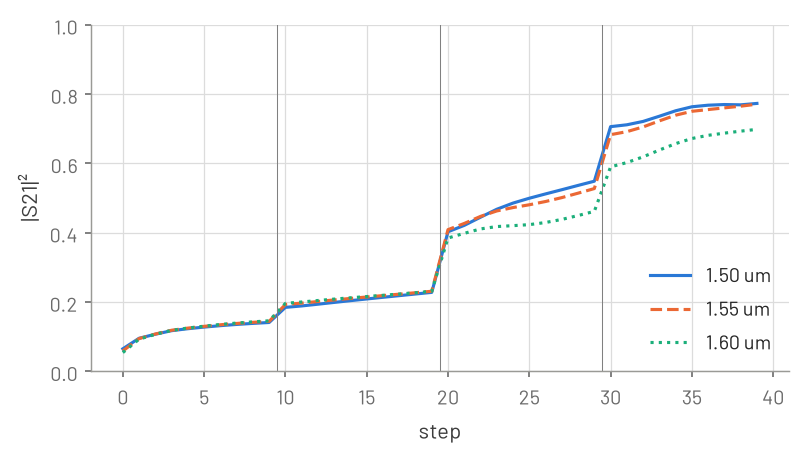

In [10]:
t_history = np.array(history)
fig, ax = plt.subplots(figsize=(6, 3))
for k, wavelength in enumerate(BAND):
    ax.plot(t_history[:, k], label=f"{wavelength / um:.2f} um")
for k in range(STEPS_PER_BETA, n_steps, STEPS_PER_BETA):
    ax.axvline(k - 0.5, color="gray", lw=0.5)
ax.set_ylim(0, 1)
ax.set_xlabel("step")
ax.set_ylabel("|S21|²")
ax.legend(loc="lower right");

## The design and its spectrum

The physical density at the four snapshots. At step 0 the filter blurs the
mirror's edge into grey gold, which absorbs, so it transmits less than the sharp
mirror. As β rises the edge sharpens into a curved gold wall that follows the turn,
and a small piece of gold fills the inner corner.

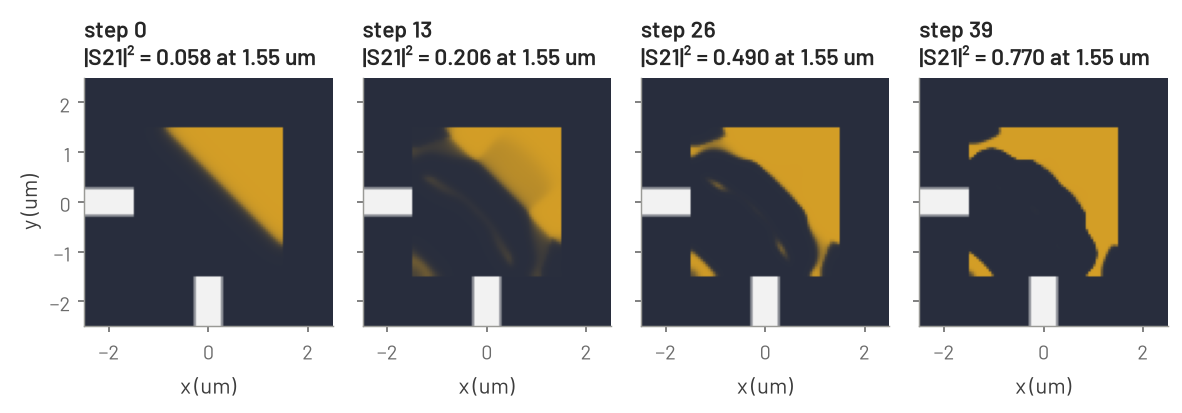

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(8, 2.6), sharey=True)
for ax, k in zip(axes, snapshot_at, strict=True):
    ax.imshow(layout(snapshots[k]), origin="lower", extent=EXTENT)
    ax.set_title(f"step {k}\n|S21|² = {history[k][1]:.3f} at 1.55 um")
    ax.set_xlabel("x (um)")
    ax.grid(False)
axes[0].set_ylabel("y (um)")
fig.tight_layout();

The design evaluated from here on is `final`: the filtered last iterate thresholded at 0.5, a
two-material image. Every number after this comes from it. A uniform sweep of nine
wavelengths, 1.45 to 1.65 µm, gives |S21|², |S11|² and the remainder
1 - |S11|² - |S21|²: the power absorbed by gold, radiated through the absorbing
boundary, or carried out in the guide's second (odd) mode. It keeps the field at
1.55 µm for a map.

In [12]:
final = (blur(0.5 * (rho + rho.T)) > 0.5).astype(float)
wavelengths = np.linspace(1.45, 1.65, 9) * um
in_um = np.round(wavelengths / um, 3)
at_f0 = int(np.argmin(np.abs(wavelengths - 1.55 * um)))


def spectrum(gold=GOLD, keep=False):
    # |S21|^2, |S11|^2 and the remainder of `final` over the nine wavelengths.
    result = gfem.solve(
        bend.with_material("design", material(final, gold)),
        gfem.Driven(
            frequency=c / wavelengths, excite="p1", keep_fields=F0 if keep else False
        ),
        options=options,
    )
    sent = np.abs(np.asarray(result.s["p2", "p1"])) ** 2
    back = np.abs(np.asarray(result.s["p1", "p1"])) ** 2
    return result, sent, back, 1 - sent - back


final_result, t_band, r_band, rest_band = spectrum(keep=True)
t_final = float(t_band[at_f0])
print(f"final: {final.mean():.1%} gold, |S21|^2 = {t_final:.4f} at 1.55 um")
print("wavelength (um)  |S21|^2  |S11|^2  remainder")
for lam, sent, back, rest in zip(in_um, t_band, r_band, rest_band, strict=True):
    print(f"{lam:15.3f}  {sent:7.4f}  {back:7.4f}  {rest:9.4f}")

final: 38.8% gold, |S21|^2 = 0.8207 at 1.55 um
wavelength (um)  |S21|^2  |S11|^2  remainder
          1.450   0.6107   0.1743     0.2150
          1.475   0.7254   0.0822     0.1924
          1.500   0.8194   0.0147     0.1659
          1.525   0.8471   0.0031     0.1498
          1.550   0.8207   0.0315     0.1477
          1.575   0.7775   0.0646     0.1579
          1.600   0.7357   0.0821     0.1822
          1.625   0.7072   0.0815     0.2113
          1.650   0.6942   0.0658     0.2401


|S21|² (solid) and the remainder (dashed) against wavelength; the shaded band is
the one the objective sees.

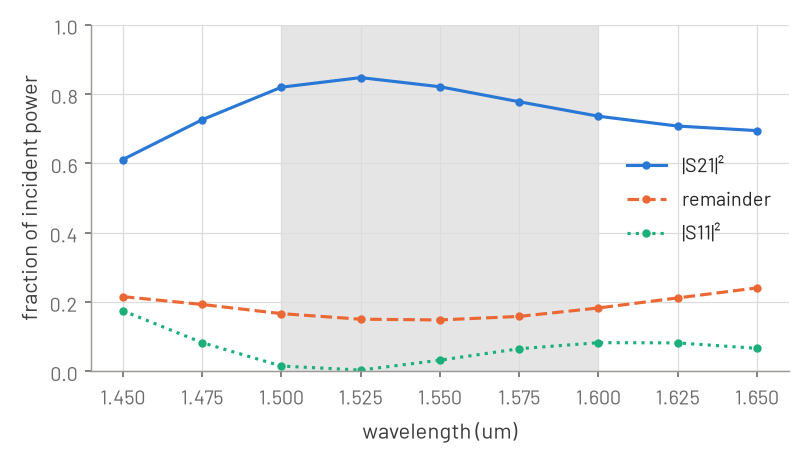

In [13]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(wavelengths / um, t_band, marker="o", ms=3, label="|S21|²")
ax.plot(wavelengths / um, rest_band, ls="--", marker="o", ms=3, label="remainder")
ax.plot(wavelengths / um, r_band, ls=":", marker="o", ms=3, label="|S11|²")
ax.axvspan(BAND[0] / um, BAND[-1] / um, color="gray", alpha=0.2, lw=0)
ax.set_ylim(0, 1)
ax.set_xlabel("wavelength (um)")
ax.set_ylabel("fraction of incident power")
ax.legend(loc="center right");

|E_z| in the mid-plane of the slab at 1.55 µm with 1 W incident at p1, sampled with
`Field.at` at 200 × 200 points. The blue line is the gold edge (ρ = 0.5).

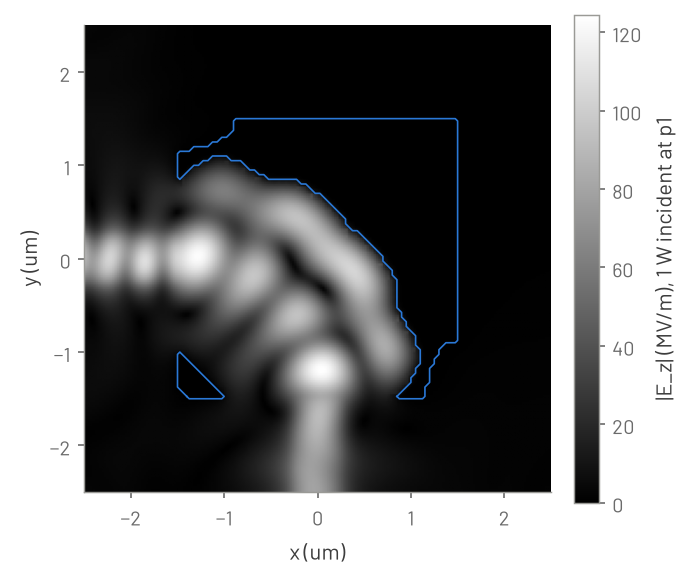

In [14]:
along_box = -HALF + (np.arange(200) + 0.5) * (2 * HALF / 200)
X, Y = np.meshgrid(along_box, along_box)
thickness = np.ptp(nodes[:, 2]) * um
plane = np.stack([X.ravel(), Y.ravel(), np.full(X.size, thickness / 2)], axis=1)
e = np.asarray(final_result.e_field(F0, excite="p1").at(plane))
ez = np.abs(e[:, 2]).reshape(X.shape) / 1e6  # MV/m
gold_map = np.zeros_like(ARMS)
gold_map[inside_design] = final
fig, ax = plt.subplots(figsize=(4.5, 3.8), layout="constrained")
image = ax.imshow(ez, origin="lower", extent=EXTENT, cmap="gray")
for line in contour_generator(centres / um, centres / um, gold_map).lines(0.5):
    ax.plot(*line.T, color="C0", ls="-", lw=0.8)
ax.set_xlabel("x (um)")
ax.set_ylabel("y (um)")
ax.grid(False)
fig.colorbar(image, ax=ax, label="|E_z| (MV/m), 1 W incident at p1");

## Trust: where the power goes

The remainder lumps three losses. Gold's share is the one the metal costs, and a
solve gives it directly: the same design with gold's damping set to 0. The lossless
metal has the same Re ε to within (γ/f)², so the fields barely move, and the
remainder falls by the power gold absorbed.

In [15]:
lossless = gfem.Material(
    eps_r=gfem.PermittivityLaw(
        eps_inf=1.0, terms=[gfem.Drude(plasma_frequency=2.183e15, damping=0.0)]
    ),
    name="lossless gold",
)
_, t_lossless, _, rest_lossless = spectrum(lossless)
absorbed = rest_band - rest_lossless
print(
    f"at 1.55 um: remainder {rest_band[at_f0]:.4f} with damping, "
    f"{rest_lossless[at_f0]:.4f} without"
)
print(f"absorbed by gold at 1.55 um: {absorbed[at_f0]:.4f} of the incident power")
print(f"absorbed over 1.45-1.65 um: {absorbed.min():.4f} to {absorbed.max():.4f}")

at 1.55 um: remainder 0.1477 with damping, 0.1304 without
absorbed by gold at 1.55 um: 0.0173 of the incident power
absorbed over 1.45-1.65 um: 0.0141 to 0.0184


## Trust: the order

Third-order elements on the same mesh bound the field discretization error at a
fixed material sampling, as the change ΔT of |S21|² at 1.55 µm. This is the largest
solve here.

In [16]:
order3 = gfem.solve(
    bend.with_material("design", material(final)),
    gfem.Driven(frequency=F0, excite="p1"),
    options=gfem.SolverOptions(linear_solver="direct", order=3),
)
t_order3 = abs(complex(order3.s["p2", "p1"][0])) ** 2
delta_t = t_order3 - t_final
print(f"order 3: |S21|^2 = {t_order3:.4f} at 1.55 um, delta T = {delta_t:+.1e}")

order 3: |S21|^2 = 0.8202 at 1.55 um, delta T = -5.5e-04


The numbers this page quotes, checked:

In [17]:
np.testing.assert_allclose(eps_band[1], -125.833 - 8.394j, atol=1e-3)
np.testing.assert_allclose(t_start["mirror"], [0.2243, 0.2108, 0.1928], atol=1e-4)
np.testing.assert_array_less(fd_error, 1e-6)
np.testing.assert_allclose(t_final, 0.82, atol=0.01)
np.testing.assert_allclose(absorbed[at_f0], 0.0175, atol=0.0025)
np.testing.assert_array_less(abs(delta_t), 2e-3)

## Limits

- **The skin depth is not resolved.** Gold's field decays in about 22 nm, inside
  one 0.1 µm cell. The order-3 check bounds the element order, not the cell size.
  Re-check a design on a mesh refined at the gold walls before trusting the second
  digit.
- **No surface plasmons.** With E along z, every gold wall in the plane is a lossy
  mirror. The other polarization, where a gold-oxide wall guides a plasmon, needs
  PMC plates instead of PEC and is not shown here.
- **Absorption is read only by the lossless re-solve.** The remainder lumps
  absorption, radiation and the odd mode; setting the damping to 0 separates the
  first.
- **The blend works on the driven uniform sweep only.** The adaptive sweep, the
  eigenmode and port mode problems raise on a law blend. Solve a blended design on
  a uniform list of frequencies.
- **The law is not a design input here.** Gold's parameters inside a blend are
  fixed. To differentiate with respect to them, give a region a law
  {py:class}`gfem.Material` instead ({doc}`../recipes/dispersive-materials`).
- **No metal on a port face.** A metal may not cross a wave port's face; keep the
  design square away from the ports, or use lumped ports.
- **Not converged.** |S21|² still rises at the last step. More steps, or a finer β
  schedule, would carry more power.
- **A lossy bend.** The {doc}`dielectric bend <bend>` carries more power at
  1.55 µm. This page shows the gradient through a metal over a band and what the
  metal costs, not a better bend.

## Next

- {doc}`../recipes/dispersive-materials`: permittivity laws on a region, their
  gradients, and which problems take them.
- {doc}`bend`: the same bend in core and cladding, with the robustness and box
  checks.
- {py:mod}`gfem.conventions`: the law forms under e^{+iωt}.
- {doc}`../capabilities`: what each problem solves and differentiates.